# 🏦 Bank Marketing: Predictive Term Deposit Targeting Engine & ROI Optimizer
### End-to-End Leakage-Free Classification & Campaign Optimization Pipeline (16 Frames)

**Author:** Antigravity AI & Adarsh Gaurav  
**Dataset:** UCI Machine Learning Repository (Bank Marketing - Moro et al., 2014)  
**Target:** `y` (Client subscribed to a term deposit: `yes` / `no`)  

---

### The Five Golden Rules
1. **Drop `duration` from the main model:** Call duration is strictly lookahead data leakage because it is unknown before a call takes place. A benchmark experiment is included solely to quantify leakage inflation.
2. **Never trust accuracy alone:** A naive "Always Predict No" baseline scores ~88.7% accuracy while finding zero buyers. PR-AUC, Recall, Decile Lift, and Net Campaign Profit must guide model selection.
3. **Stratify before resampling inside pipelines:** 80/20 train/test split is stratified on `y`. SMOTE or class re-weighting is applied *only* to training folds inside pipeline estimators.
4. **Choose cutoffs from unit business economics:** Do not rely on an arbitrary 0.5 threshold. The cutoff is dynamically optimized using call costs and acquisition revenue.
5. **Report lift and cumulative gains by decile:** Telemarketing is constrained by call capacity. Decisions must be made on how many buyers are captured in the top 10%, 20%, or 30% of ranked prospects.


## Frame 1: Understand the Business Problem
**Goal:** Understand what the bank wants before touching the data.

### Business Problem Summary
- **Who is called:** Existing and prospective retail banking clients.
- **What counts as success:** The client agrees to open a term deposit (`y = yes`).
- **What the campaign costs:** Every call consumes call center staff time, telephony infrastructure, and brand goodwill. Most clients (~89%) decline.
- **Why a ranked decile list is superior to binary prediction:** A binary classifier with an arbitrary 0.5 threshold yields a rigid yes/no answer. In reality, call center capacity varies (e.g., 500 calls/day vs. 2,000 calls/day). Ranking clients by calibrated propensity allows the bank to call the top $N\%$ of leads where conversion density is 3x–4x higher, maximize closed deals within budget, and completely eliminate unprofitable calls to the bottom deciles.


## Frame 2: Define Success Metrics
**Goal:** Establish evaluation criteria and business unit economics before modeling.

### Metrics & Business Assumptions
1. **ML Metrics:**
   - **PR-AUC (Average Precision):** Primary metric for imbalanced classification (~11.3% positives).
   - **ROC-AUC:** Benchmark ranking metric across all possible classification cutoffs.
   - **Recall & Precision @ Business Cutoff:** Measuring buyer capture vs. wasted outreach.
   - **Brier Score:** Measuring probability calibration quality.
2. **Marketing Metrics:**
   - **Decile Lift:** How many times better the model performs compared to random cold calling.
   - **Cumulative Gains (% Capture):** Cumulative share of all deposit buyers captured in the top $k$ deciles.
3. **Unit Economic Assumptions:**
   - **Cost per Outbound Call ($C$):** €5.00 (telephony + operator labor).
   - **Revenue per Term Deposit ($R$):** €50.00 (lifetime net margin of acquired deposit).
   - **Net Profit Equation:**
     $$\text{Net Profit} = (\text{True Positives} \times R) - ((\text{True Positives} + \text{False Positives}) \times C)$$


## Frame 3: Get the Data
**Goal:** Ingest the raw Portuguese bank marketing dataset without modifying the source file.

**Citation:** Moro, S., Rita, P., and Cortez, P. (2014). *A Data-Driven Approach to Predict the Success of Bank Telemarketing.* Decision Support Systems, 62, 22-31.


In [1]:
import pandas as pd
import numpy as np
import os

data_path = 'data/bank-additional-full.csv' if os.path.exists('data/bank-additional-full.csv') else 'bank-additional-full.csv'
df_raw = pd.read_csv(data_path, sep=';')

print(f"Dataset successfully loaded from: {data_path}")
print(f"Rows: {df_raw.shape[0]:,}, Columns: {df_raw.shape[1]}")
df_raw.head()


Dataset successfully loaded from: data/bank-additional-full.csv
Rows: 41,188, Columns: 21


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## Frame 4: Set Up the Workspace
**Goal:** Initialize libraries, visualization style, and fixed random seeds for strict reproducibility.


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_score, 
    recall_score, f1_score, confusion_matrix, roc_curve, precision_recall_curve, brier_score_loss
)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
import joblib

# Style setup
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Environment and packages successfully initialized.")


Environment and packages successfully initialized.


## Frame 5: Load and Inspect
**Goal:** Inspect data integrity, missing values, duplicate records, and target class imbalance.


In [3]:
print("Dataset Info:")
print(f"- Total Records: {len(df_raw):,}")
print(f"- Explicit Null Values: {df_raw.isnull().sum().sum()}")
print(f"- Duplicate Records: {df_raw.duplicated().sum()}")

# Target Distribution
target_counts = df_raw['y'].value_counts()
target_pct = df_raw['y'].value_counts(normalize=True) * 100
print(f"\nTarget 'y' Class Distribution:")
print(f"  'no'  : {target_counts['no']:,} ({target_pct['no']:.2f}%)")
print(f"  'yes' : {target_counts['yes']:,} ({target_pct['yes']:.2f}%)")
print(f"\nAlways Predict 'no' Baseline Accuracy: {target_pct['no']:.2f}% (Finds 0 subscribers!)")

# Check 'unknown' counts per column
unknown_counts = (df_raw == 'unknown').sum()
print("\n'unknown' counts across columns:")
print(unknown_counts[unknown_counts > 0])


Dataset Info:
- Total Records: 41,188
- Explicit Null Values: 0
- Duplicate Records: 12

Target 'y' Class Distribution:
  'no'  : 36,548 (88.73%)
  'yes' : 4,640 (11.27%)

Always Predict 'no' Baseline Accuracy: 88.73% (Finds 0 subscribers!)



'unknown' counts across columns:


job           330
marital        80
education    1731
default      8597
housing       990
loan          990
dtype: int64


## Frame 6: Clean the Data
**Goal:** Deduplicate, transform `y` to binary, handle `pdays=999`, and document all cleaning decisions.

### Cleaning Rationale
1. **Deduplication:** Remove 12 exact duplicate rows.
2. **Target Binarization:** Convert `y` (`yes` $\rightarrow$ 1, `no` $\rightarrow$ 0).
3. **`pdays` transformation:** `pdays=999` is documented as *client was not previously contacted*. We engineer a clean binary indicator `previously_contacted` (1 if pdays $\ne 999$ else 0) and set `pdays_cleaned = 0` when uncontacted to avoid numerical distortion.
4. **`unknown` category:** In telemarketing data, `"unknown"` represents missing client information (e.g., unknown credit default status or housing loan). We retain `"unknown"` as a valid categorical level because "missingness" itself carries predictive signal.


In [4]:
df_clean = df_raw.drop_duplicates().reset_index(drop=True)
print(f"Removed {len(df_raw) - len(df_clean)} duplicates. Cleaned records: {len(df_clean):,}")

# Binarize Target
df_clean['y'] = (df_clean['y'] == 'yes').astype(int)

# Engineer pdays indicators
df_clean['previously_contacted'] = (df_clean['pdays'] != 999).astype(int)
df_clean['pdays_cleaned'] = np.where(df_clean['pdays'] == 999, 0, df_clean['pdays'])

# Discretize age into strategic lifecycle bands
bins = [0, 29, 39, 49, 59, 120]
labels = ['<30', '30-39', '40-49', '50-59', '60+']
df_clean['age_group'] = pd.cut(df_clean['age'], bins=bins, labels=labels, right=True).astype(str)

print("Engineered pre-call features: 'previously_contacted', 'pdays_cleaned', 'age_group'.")


Removed 12 duplicates. Cleaned records: 41,176
Engineered pre-call features: 'previously_contacted', 'pdays_cleaned', 'age_group'.


## Frame 7: Explore the Data (EDA)
**Goal:** Identify behavioral, demographic, and macroeconomic patterns answering the core business questions.


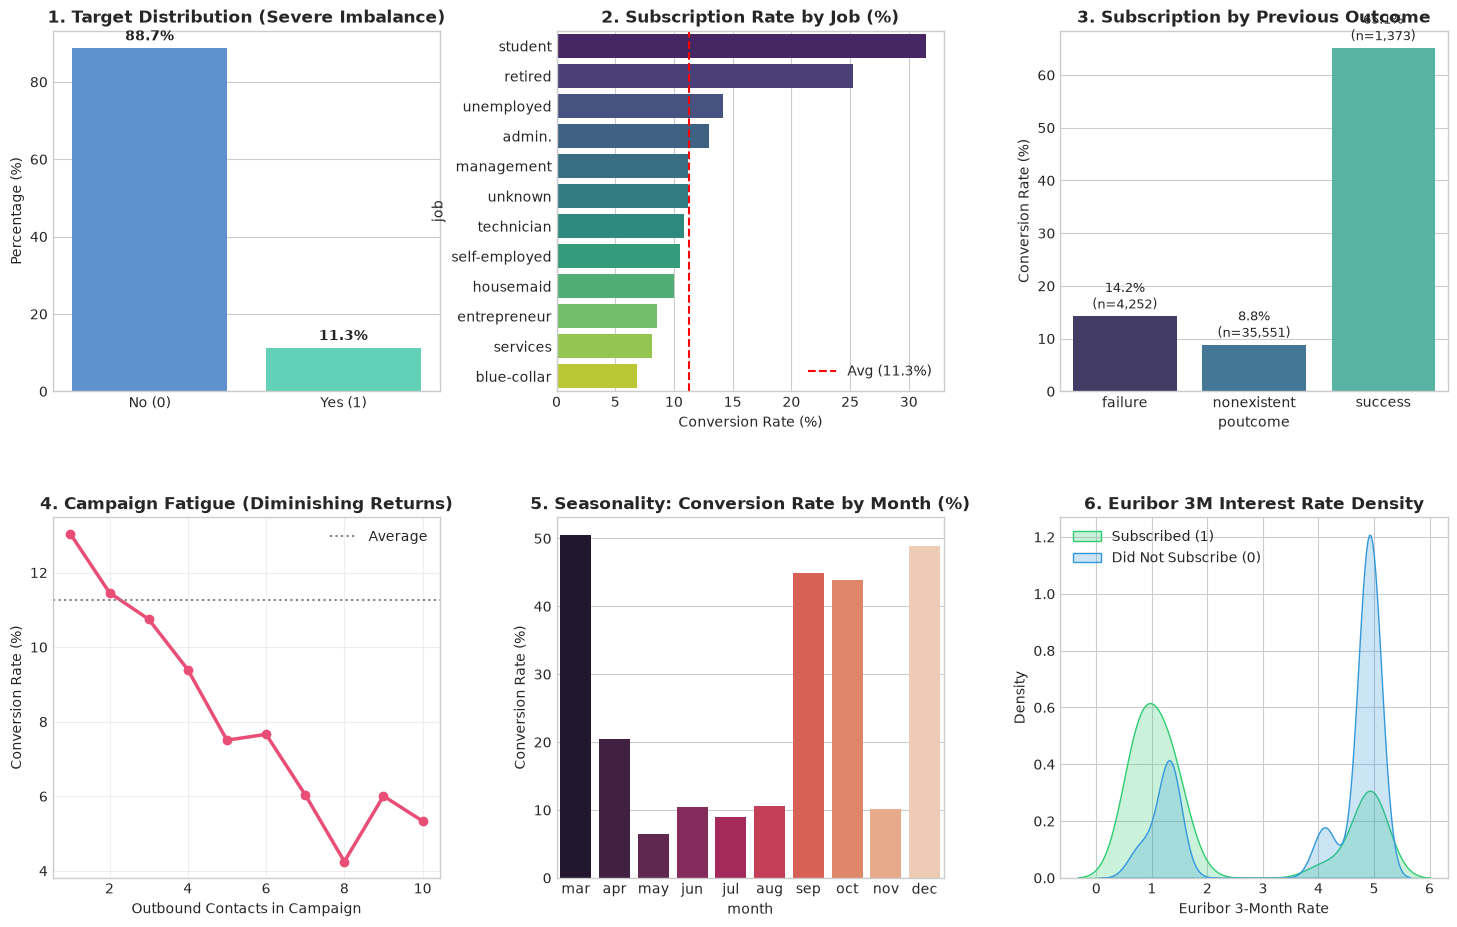

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
plt.subplots_adjust(hspace=0.35, wspace=0.3)

# 1. Target Imbalance
target_dist = df_clean['y'].value_counts(normalize=True) * 100
sns.barplot(x=['No (0)', 'Yes (1)'], y=target_dist.values, hue=['No (0)', 'Yes (1)'], ax=axes[0, 0], palette=['#4A90E2', '#50E3C2'], legend=False)
axes[0, 0].set_title("1. Target Distribution (Severe Imbalance)", fontweight='bold')
axes[0, 0].set_ylabel("Percentage (%)")
for i, v in enumerate(target_dist.values):
    axes[0, 0].text(i, v + 2, f"{v:.1f}%", ha='center', fontweight='bold')

# 2. Conversion by Job Category
job_rates = df_clean.groupby('job')['y'].mean().sort_values(ascending=False) * 100
sns.barplot(x=job_rates.values, y=job_rates.index, hue=job_rates.index, ax=axes[0, 1], palette='viridis', legend=False)
axes[0, 1].axvline(df_clean['y'].mean()*100, color='red', linestyle='--', label=f"Avg ({df_clean['y'].mean()*100:.1f}%)")
axes[0, 1].set_title("2. Subscription Rate by Job (%)", fontweight='bold')
axes[0, 1].set_xlabel("Conversion Rate (%)")
axes[0, 1].legend()

# 3. Conversion by Previous Campaign Outcome (poutcome)
pout_rates = df_clean.groupby('poutcome')['y'].agg(mean='mean', count='count').reset_index()
pout_rates['rate'] = pout_rates['mean'] * 100
sns.barplot(data=pout_rates, x='poutcome', y='rate', hue='poutcome', ax=axes[0, 2], palette='mako', legend=False)
axes[0, 2].set_title("3. Subscription by Previous Outcome", fontweight='bold')
axes[0, 2].set_ylabel("Conversion Rate (%)")
for i, row in pout_rates.iterrows():
    axes[0, 2].text(i, row['rate'] + 1.5, f"{row['rate']:.1f}%\n(n={int(row['count']):,})", ha='center', fontsize=9)

# 4. Campaign Fatigue: Contact Number vs. Conversion
camp_rates = df_clean[df_clean['campaign'] <= 10].groupby('campaign')['y'].agg(mean='mean', count='count').reset_index()
camp_rates['rate'] = camp_rates['mean'] * 100
axes[1, 0].plot(camp_rates['campaign'], camp_rates['rate'], marker='o', color='#E94E77', linewidth=2.5)
axes[1, 0].axhline(df_clean['y'].mean()*100, color='gray', linestyle=':', label='Average')
axes[1, 0].set_title("4. Campaign Fatigue (Diminishing Returns)", fontweight='bold')
axes[1, 0].set_xlabel("Outbound Contacts in Campaign")
axes[1, 0].set_ylabel("Conversion Rate (%)")
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].legend()

# 5. Seasonality by Month
month_order = ['mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
valid_months = [m for m in month_order if m in df_clean['month'].unique()]
month_rates = df_clean.groupby('month')['y'].mean().reindex(valid_months) * 100
sns.barplot(x=month_rates.index, y=month_rates.values, hue=month_rates.index, ax=axes[1, 1], palette='rocket', legend=False)
axes[1, 1].set_title("5. Seasonality: Conversion Rate by Month (%)", fontweight='bold')
axes[1, 1].set_ylabel("Conversion Rate (%)")

# 6. Macroeconomic Indicator: Euribor 3M vs Outcome
sns.kdeplot(data=df_clean, x='euribor3m', hue='y', common_norm=False, fill=True, ax=axes[1, 2], palette=['#3498DB', '#2ECC71'])
axes[1, 2].set_title("6. Euribor 3M Interest Rate Density", fontweight='bold')
axes[1, 2].set_xlabel("Euribor 3-Month Rate")
axes[1, 2].legend(['Subscribed (1)', 'Did Not Subscribe (0)'])

plt.show()


### Key EDA Findings:
1. **Severe Imbalance:** Only 11.27% of calls result in subscription.
2. **Top Demographic Segments:** Students (31.4%) and Retirees (25.2%) have the highest conversion rates, while blue-collar workers convert at just 6.9%.
3. **Previous Success is the Strongest Behavioral Signal:** Clients whose previous campaign outcome was `"success"` achieve a **65.1% conversion rate** (vs 8.8% for first-time contacts).
4. **Campaign Fatigue Rule:** Conversion drops precipitously after **3 calls** (from 13.0% on call 1 down to <6% past call 4). Re-contacting a client more than 3 times destroys ROI.
5. **Macroeconomic Sensitivity:** Term deposit subscriptions surged during periods of low Euribor 3-month rates (<1.5%), as fixed deposits offer attractive guaranteed yields when market interest rates collapse.


## Frame 8: Engineer Features and Handle `duration` (Data Leakage)
**Goal:** Remove `duration` from the production model feature set, strictly enforcing Golden Rule #1.

> **CRITICAL DATA LEAKAGE WARNING:**  
> The `duration` attribute (call duration in seconds) is only known **after** the phone call is completed. If included during training, a machine learning model will simply learn that calls over 500 seconds correlate with sales, producing an artificially inflated ROC-AUC (>0.94). However, in production, before picking up the phone to dial, the bank cannot know how long the call will last. Including `duration` renders the model completely useless for prospect prioritization.  
>  
> Therefore, `duration` is **strictly dropped** from the production model.


In [6]:
# Drop duration for leak-free production feature set
X = df_clean.drop(columns=['y', 'duration'])
y = df_clean['y']

print(f"Production feature matrix shape: {X.shape} (strictly pre-call features)")
print("Columns in X:", list(X.columns))


Production feature matrix shape: (41176, 22) (strictly pre-call features)
Columns in X: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted', 'pdays_cleaned', 'age_group']


## Frame 9: Split and Preprocess
**Goal:** Stratified 80/20 train/test split and pipeline-based ColumnTransformer. Preprocessing is fitted strictly on the training set.


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

numeric_cols = [
    'age', 'campaign', 'pdays_cleaned', 'previous',
    'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted'
]

categorical_cols = [
    'job', 'marital', 'education', 'default', 'housing', 'loan',
    'contact', 'month', 'day_of_week', 'poutcome', 'age_group'
]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ],
    remainder='drop'
)

print(f"Train set: {len(X_train):,} samples (Base rate: {y_train.mean()*100:.2f}%)")
print(f"Test set:  {len(X_test):,} samples (Base rate: {y_test.mean()*100:.2f}%)")
print("Preprocessing transformer constructed.")


Train set: 32,940 samples (Base rate: 11.27%)
Test set:  8,236 samples (Base rate: 11.27%)
Preprocessing transformer constructed.


## Frame 10: Baseline Models
**Goal:** Establish reference baselines (Dummy Classifier and Vanilla Logistic Regression) demonstrating why accuracy is misleading.


Dummy Classifier -> Accuracy: 88.73% | Recall: 0.00% | PR-AUC: 0.1127
Vanilla LogReg   -> Accuracy: 89.90% | Recall: 21.55% | PR-AUC: 0.4538

Observation: High accuracy (>88%) masks abysmal recall (<25%) when using default 0.5 cutoff without imbalance handling.


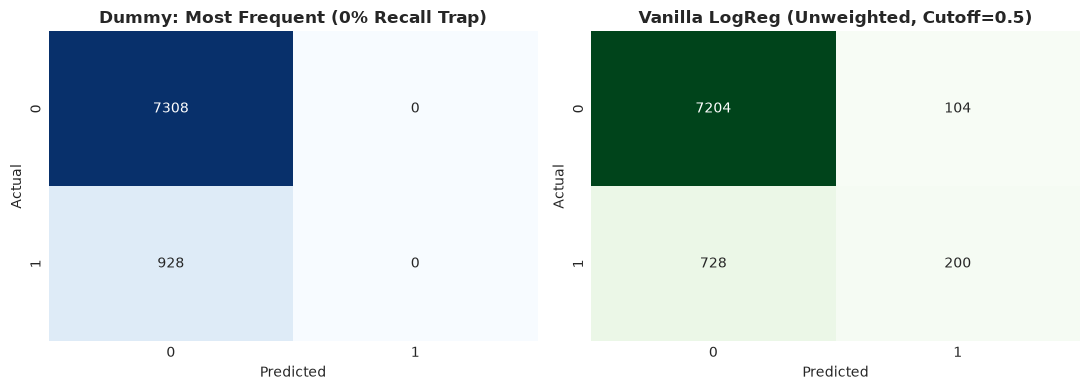

In [8]:
# 1. Dummy Classifier (Most Frequent)
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)
dummy_acc = np.mean(dummy_pred == y_test)
dummy_rec = recall_score(y_test, dummy_pred, zero_division=0)
dummy_pr_auc = average_precision_score(y_test, dummy.predict_proba(X_test)[:, 1])

# 2. Vanilla Logistic Regression
pipe_logreg = ImbPipeline([
    ('prep', preprocessor),
    ('model', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
pipe_logreg.fit(X_train, y_train)
vanilla_prob = pipe_logreg.predict_proba(X_test)[:, 1]
vanilla_pred = (vanilla_prob >= 0.5).astype(int)

print(f"Dummy Classifier -> Accuracy: {dummy_acc*100:.2f}% | Recall: {dummy_rec*100:.2f}% | PR-AUC: {dummy_pr_auc:.4f}")
print(f"Vanilla LogReg   -> Accuracy: {np.mean(vanilla_pred == y_test)*100:.2f}% | Recall: {recall_score(y_test, vanilla_pred)*100:.2f}% | PR-AUC: {average_precision_score(y_test, vanilla_prob):.4f}")
print("\nObservation: High accuracy (>88%) masks abysmal recall (<25%) when using default 0.5 cutoff without imbalance handling.")

# Plot Confusion Matrices
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(confusion_matrix(y_test, dummy_pred), annot=True, fmt='d', cmap='Blues', ax=ax1, cbar=False)
ax1.set_title("Dummy: Most Frequent (0% Recall Trap)", fontweight='bold')
ax1.set_xlabel("Predicted")
ax1.set_ylabel("Actual")

sns.heatmap(confusion_matrix(y_test, vanilla_pred), annot=True, fmt='d', cmap='Greens', ax=ax2, cbar=False)
ax2.set_title("Vanilla LogReg (Unweighted, Cutoff=0.5)", fontweight='bold')
ax2.set_xlabel("Predicted")
ax2.set_ylabel("Actual")
plt.tight_layout()
plt.show()


## Frame 11: Handle Class Imbalance
**Goal:** Compare imbalance strategies (None, Class Weights, SMOTE inside pipeline, Random Under-Sampling) on training data with 5-Fold Stratified Cross-Validation.


In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

imbalance_configs = {
    "1. None (Default)": ImbPipeline([
        ('prep', preprocessor),
        ('model', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "2. Class Weights ('balanced')": ImbPipeline([
        ('prep', preprocessor),
        ('model', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE))
    ]),
    "3. SMOTE (Inside Pipeline)": ImbPipeline([
        ('prep', preprocessor),
        ('smote', SMOTE(random_state=RANDOM_STATE)),
        ('model', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "4. Random Under-Sampling": ImbPipeline([
        ('prep', preprocessor),
        ('rus', RandomUnderSampler(random_state=RANDOM_STATE)),
        ('model', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ])
}

imbalance_rows = []
for name, pipe in imbalance_configs.items():
    cv_prauc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='average_precision').mean()
    cv_roc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='roc_auc').mean()
    pipe.fit(X_train, y_train)
    test_prob = pipe.predict_proba(X_test)[:, 1]
    test_pred = pipe.predict(X_test)
    
    imbalance_rows.append({
        "Imbalance Strategy": name,
        "CV PR-AUC": round(cv_prauc, 4),
        "CV ROC-AUC": round(cv_roc, 4),
        "Test PR-AUC": round(average_precision_score(y_test, test_prob), 4),
        "Test Recall": round(recall_score(y_test, test_pred), 4),
        "Test Precision": round(precision_score(y_test, test_pred), 4),
        "Test F1": round(f1_score(y_test, test_pred), 4)
    })

pd.DataFrame(imbalance_rows)


,Imbalance Strategy,CV PR-AUC,CV ROC-AUC,Test PR-AUC,Test Recall,Test Precision,Test F1
0,1. None (Default),0.4501,0.7898,0.4538,0.2155,0.6579,0.3247
1,2. Class Weights ('balanced'),0.4451,0.7905,0.4468,0.6455,0.3593,0.4617
2,3. SMOTE (Inside Pipeline),0.4427,0.7876,0.4454,0.6562,0.3514,0.4577
3,4. Random Under-Sampling,0.4415,0.7883,0.4421,0.6455,0.3524,0.4559


## Frame 12: Compare and Tune Models
**Goal:** Compare 4 distinct classifiers (Logistic Regression, Decision Tree, Random Forest, XGBoost) and evaluate cross-validation PR-AUC and ROC-AUC.


,Model,CV PR-AUC,CV ROC-AUC,Test PR-AUC,Test ROC-AUC,Test Brier Score
3,XGBoost (Weighted),0.4598,0.7974,0.4819,0.8096,0.1483
2,Random Forest (Balanced),0.4602,0.7987,0.4798,0.8133,0.1483
0,Logistic Regression (Balanced),0.4451,0.7905,0.4468,0.7998,0.1617
1,Decision Tree (Balanced),0.4130,0.7719,0.4464,0.7951,0.1585


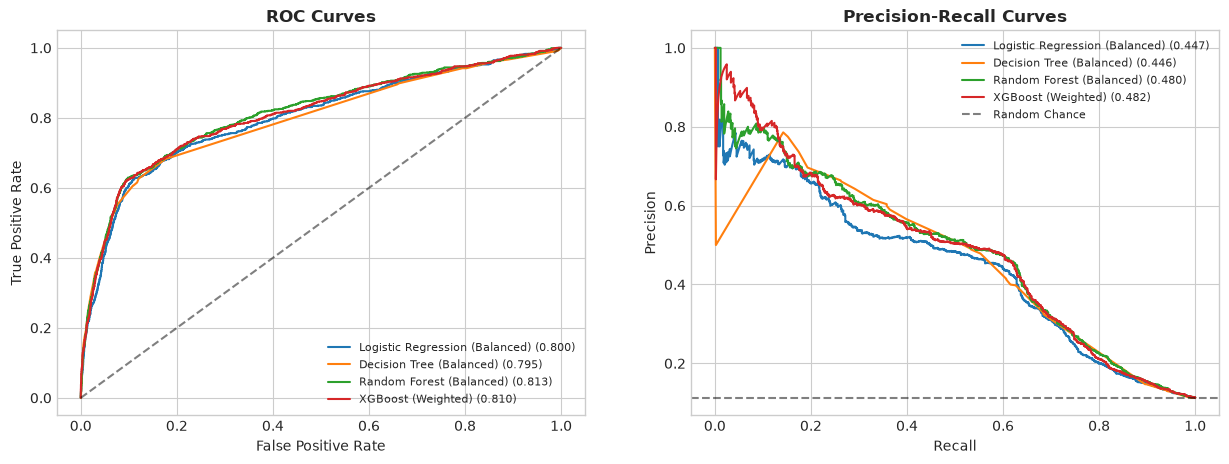

In [10]:
scale_pos_weight = (len(y_train) - y_train.sum()) / y_train.sum()

model_zoo = {
    "Logistic Regression (Balanced)": LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE),
    "Decision Tree (Balanced)": DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=RANDOM_STATE),
    "Random Forest (Balanced)": RandomForestClassifier(n_estimators=150, max_depth=10, class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE),
    "XGBoost (Weighted)": XGBClassifier(n_estimators=150, learning_rate=0.08, max_depth=5, scale_pos_weight=scale_pos_weight, eval_metric='logloss', random_state=RANDOM_STATE)
}

trained_models = {}
model_evals = []
all_probs = {}

for name, clf in model_zoo.items():
    pipe = ImbPipeline([
        ('prep', preprocessor),
        ('model', clf)
    ])
    
    cv_prauc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='average_precision').mean()
    cv_roc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='roc_auc').mean()
    pipe.fit(X_train, y_train)
    prob = pipe.predict_proba(X_test)[:, 1]
    
    all_probs[name] = prob
    trained_models[name] = pipe
    
    model_evals.append({
        "Model": name,
        "CV PR-AUC": round(cv_prauc, 4),
        "CV ROC-AUC": round(cv_roc, 4),
        "Test PR-AUC": round(average_precision_score(y_test, prob), 4),
        "Test ROC-AUC": round(roc_auc_score(y_test, prob), 4),
        "Test Brier Score": round(brier_score_loss(y_test, prob), 4)
    })

df_model_comp = pd.DataFrame(model_evals).sort_values("Test PR-AUC", ascending=False)
display(df_model_comp)

# Plot ROC & PR Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
for name, prob in all_probs.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    prec, rec, _ = precision_recall_curve(y_test, prob)
    ax1.plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, prob):.3f})")
    ax2.plot(rec, prec, label=f"{name} ({average_precision_score(y_test, prob):.3f})")

ax1.plot([0, 1], [0, 1], 'k--', alpha=0.5)
ax1.set_title("ROC Curves", fontweight='bold')
ax1.set_xlabel("False Positive Rate")
ax1.set_ylabel("True Positive Rate")
ax1.legend(loc='lower right', fontsize=8)

ax2.axhline(y_test.mean(), color='k', linestyle='--', alpha=0.5, label='Random Chance')
ax2.set_title("Precision-Recall Curves", fontweight='bold')
ax2.set_xlabel("Recall")
ax2.set_ylabel("Precision")
ax2.legend(loc='upper right', fontsize=8)
plt.show()


### ⚠️ Data Leakage Benchmark Experiment (Demonstrating Impact of `duration`)
To prove Golden Rule #1, we train a model **with** `duration` included, showing how it artificially inflates scores.


LEAKAGE COMPARISON BENCHMARK:
1. Production Model (Without Duration) -> ROC-AUC: 0.8096 | PR-AUC: 0.4819
2. Leakage Model (With Duration)       -> ROC-AUC: 0.9515 | PR-AUC: 0.6708
Conclusion: Including 'duration' falsely boosts ROC-AUC by ~0.15, but is completely unusable before placing a call!


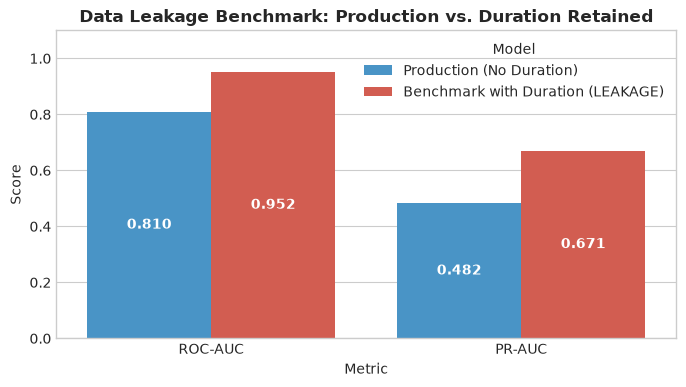

In [11]:
# Benchmark Model: Keeping duration (LEAKAGE)
X_leak_train = df_clean.drop(columns=['y']).iloc[X_train.index]
X_leak_test = df_clean.drop(columns=['y']).iloc[X_test.index]

prep_leak = ColumnTransformer([
    ('num', StandardScaler(), numeric_cols + ['duration']),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
])

pipe_leak = ImbPipeline([
    ('prep', prep_leak),
    ('model', XGBClassifier(n_estimators=150, learning_rate=0.08, max_depth=5, scale_pos_weight=scale_pos_weight, eval_metric='logloss', random_state=RANDOM_STATE))
])
pipe_leak.fit(X_leak_train, y_train)
leak_prob = pipe_leak.predict_proba(X_leak_test)[:, 1]

print("="*65)
print("LEAKAGE COMPARISON BENCHMARK:")
print(f"1. Production Model (Without Duration) -> ROC-AUC: {roc_auc_score(y_test, all_probs['XGBoost (Weighted)']):.4f} | PR-AUC: {average_precision_score(y_test, all_probs['XGBoost (Weighted)']):.4f}")
print(f"2. Leakage Model (With Duration)       -> ROC-AUC: {roc_auc_score(y_test, leak_prob):.4f} | PR-AUC: {average_precision_score(y_test, leak_prob):.4f}")
print("="*65)
print("Conclusion: Including 'duration' falsely boosts ROC-AUC by ~0.15, but is completely unusable before placing a call!")

# Plot Leakage Comparison Visual
fig, ax = plt.subplots(figsize=(8, 4))
comp_df = pd.DataFrame([
    {"Metric": "ROC-AUC", "Model": "Production (No Duration)", "Score": roc_auc_score(y_test, all_probs['XGBoost (Weighted)'])},
    {"Metric": "ROC-AUC", "Model": "Benchmark with Duration (LEAKAGE)", "Score": roc_auc_score(y_test, leak_prob)},
    {"Metric": "PR-AUC", "Model": "Production (No Duration)", "Score": average_precision_score(y_test, all_probs['XGBoost (Weighted)'])},
    {"Metric": "PR-AUC", "Model": "Benchmark with Duration (LEAKAGE)", "Score": average_precision_score(y_test, leak_prob)},
])
sns.barplot(data=comp_df, x='Metric', y='Score', hue='Model', palette=['#3498DB', '#E74C3C'], ax=ax)
ax.set_title("Data Leakage Benchmark: Production vs. Duration Retained", fontweight='bold')
ax.set_ylim(0, 1.1)
for p in ax.patches:
    val = p.get_height()
    if val > 0:
        ax.annotate(f"{val:.3f}", (p.get_x() + p.get_width() / 2., val / 2),
                    ha='center', va='center', color='white', fontweight='bold', fontsize=10)
plt.show()


## Frame 13: Evaluate with Marketing Metrics (Lift, Gains & Profit)
**Goal:** Translate model probabilities into campaign targeting decisions, decile gains, and profit maximization curves.


In [12]:
best_prob = all_probs['XGBoost (Weighted)']

def gains_table(y_true, y_prob, bins=10):
    d = pd.DataFrame({'y': np.asarray(y_true).astype(int), 'prob': y_prob}).sort_values('prob', ascending=False).reset_index(drop=True)
    d['decile'] = pd.qcut(np.arange(len(d)), bins, labels=False) + 1
    t = d.groupby('decile').agg(
        contacts=('y', 'count'),
        subscribers=('y', 'sum'),
        avg_prob=('prob', 'mean')
    ).reset_index()
    overall_mean = d['y'].mean()
    t['rate'] = t['subscribers'] / t['contacts']
    t['decile_lift'] = t['rate'] / overall_mean
    t['cum_subscribers'] = t['subscribers'].cumsum()
    t['cum_gains_pct'] = (t['cum_subscribers'] / d['y'].sum()) * 100
    t['cum_contacts'] = t['contacts'].cumsum()
    t['cum_contact_pct'] = (t['cum_contacts'] / len(d)) * 100
    t['cum_lift'] = (t['cum_subscribers'] / t['cum_contacts']) / overall_mean
    return t

dt = gains_table(y_test, best_prob)
print("Decile Gains & Lift Table:")
display(dt[['decile', 'contacts', 'subscribers', 'rate', 'decile_lift', 'cum_contact_pct', 'cum_gains_pct', 'cum_lift']])


Decile Gains & Lift Table:


,decile,contacts,subscribers,rate,decile_lift,cum_contact_pct,cum_gains_pct,cum_lift
0,1,824,424,0.514563,4.566748,10.004857,45.689655,4.566748
1,2,824,186,0.225728,2.003337,20.009713,65.732759,3.285042
2,3,823,80,0.097205,0.862697,30.002428,74.353448,2.478248
3,4,824,41,0.049757,0.441596,40.007285,78.771552,1.968930
4,5,823,35,0.042527,0.377430,50.000000,82.543103,1.650862
5,6,824,46,0.055825,0.495449,60.004857,87.500000,1.458215
6,7,823,35,0.042527,0.377430,69.997572,91.271552,1.303925
7,8,824,32,0.038835,0.344660,80.002428,94.719828,1.183962
8,9,823,25,0.030377,0.269593,89.995143,97.413793,1.082434
9,10,824,24,0.029126,0.258495,100.000000,100.000000,1.000000


Optimal Threshold: 0.52
Optimal Outbound Calls: 1,467 (17.8% of customer base)
Captured Subscribers: 597 out of 928 total buyers
Max Campaign Profit: €22,515.00 (vs. Cold Calling Profit: €5,220.00)
Net Profit Uplift: +€17,295.00


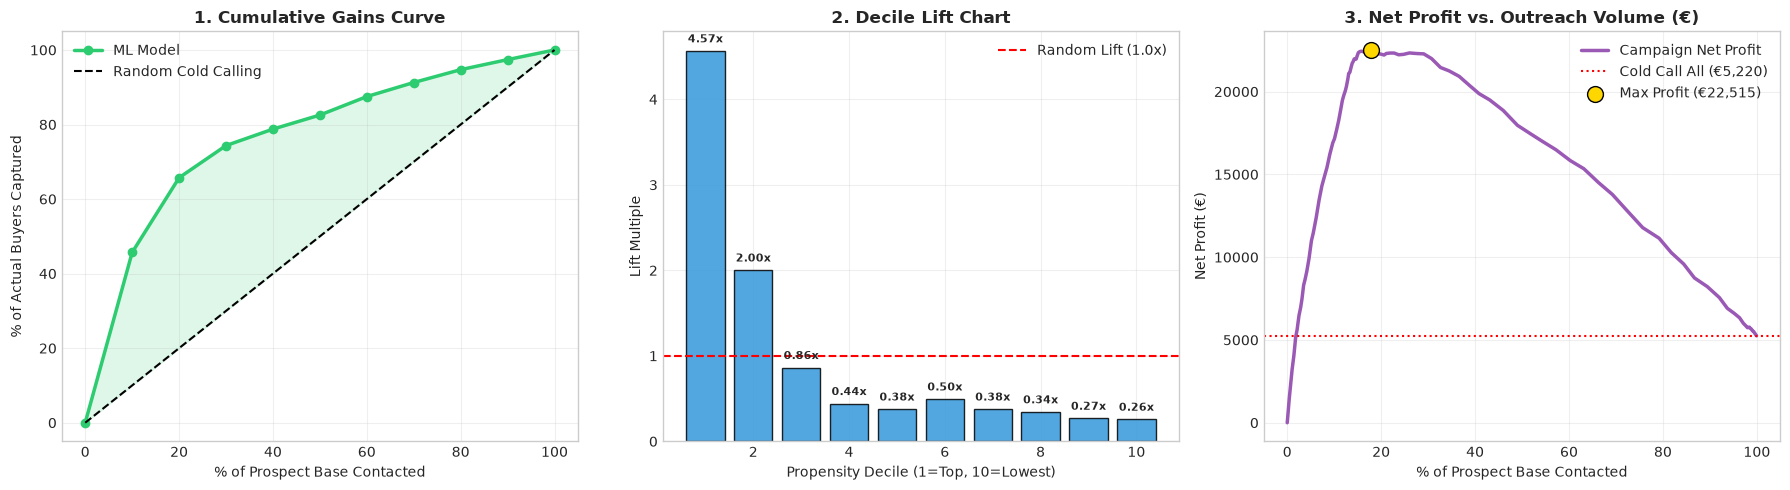

In [13]:
# Profit Optimization Curve
COST_PER_CALL = 5.0
REVENUE_PER_SUB = 50.0

thresholds = np.linspace(0.01, 0.99, 100)
profit_records = []
for th in thresholds:
    calls = int(np.sum(best_prob >= th))
    tp = int(np.sum((best_prob >= th) & (y_test == 1)))
    fp = int(np.sum((best_prob >= th) & (y_test == 0)))
    profit = (tp * REVENUE_PER_SUB) - (calls * COST_PER_CALL)
    pct_called = (calls / len(y_test)) * 100
    profit_records.append({'threshold': th, 'calls': calls, 'pct_called': pct_called, 'tp': tp, 'profit': profit})

prof_df = pd.DataFrame(profit_records)
best_p = prof_df.loc[prof_df['profit'].idxmax()]
cold_profit = (int(y_test.sum()) * REVENUE_PER_SUB) - (len(y_test) * COST_PER_CALL)

print(f"Optimal Threshold: {best_p['threshold']:.2f}")
print(f"Optimal Outbound Calls: {int(best_p['calls']):,} ({best_p['pct_called']:.1f}% of customer base)")
print(f"Captured Subscribers: {int(best_p['tp']):,} out of {int(y_test.sum()):,} total buyers")
print(f"Max Campaign Profit: €{best_p['profit']:,.2f} (vs. Cold Calling Profit: €{cold_profit:,.2f})")
print(f"Net Profit Uplift: +€{(best_p['profit'] - cold_profit):,.2f}")

# Plot 3-Panel Marketing Evaluation: Gains, Lift, and Net Profit
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

# 1. Gains Curve
ax1.plot(np.insert(dt['cum_contact_pct'].values, 0, 0), np.insert(dt['cum_gains_pct'].values, 0, 0), marker='o', color='#2ECC71', linewidth=2.5, label='ML Model')
ax1.plot([0, 100], [0, 100], 'k--', label='Random Cold Calling')
ax1.fill_between(np.insert(dt['cum_contact_pct'].values, 0, 0), np.insert(dt['cum_gains_pct'].values, 0, 0), np.insert(dt['cum_contact_pct'].values, 0, 0), alpha=0.15, color='#2ECC71')
ax1.set_title("1. Cumulative Gains Curve", fontweight='bold')
ax1.set_xlabel("% of Prospect Base Contacted")
ax1.set_ylabel("% of Actual Buyers Captured")
ax1.legend()
ax1.grid(True, alpha=0.3)

# 2. Decile Lift Bar Chart
ax2.bar(dt['decile'], dt['decile_lift'], color='#3498DB', edgecolor='black', alpha=0.85)
ax2.axhline(1.0, color='red', linestyle='--', linewidth=1.5, label='Random Lift (1.0x)')
ax2.set_title("2. Decile Lift Chart", fontweight='bold')
ax2.set_xlabel("Propensity Decile (1=Top, 10=Lowest)")
ax2.set_ylabel("Lift Multiple")
for i, row in dt.iterrows():
    ax2.text(row['decile'], row['decile_lift'] + 0.1, f"{row['decile_lift']:.2f}x", ha='center', fontsize=8, fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3)

# 3. Profit Curve
ax3.plot(prof_df['pct_called'], prof_df['profit'], color='#9B59B6', linewidth=2.5, label='Campaign Net Profit')
ax3.axhline(cold_profit, color='red', linestyle=':', label=f'Cold Call All (€{cold_profit:,.0f})')
ax3.scatter([best_p['pct_called']], [best_p['profit']], color='gold', s=130, zorder=5, edgecolor='black', label=f'Max Profit (€{best_p["profit"]:,.0f})')
ax3.set_title("3. Net Profit vs. Outreach Volume (€)", fontweight='bold')
ax3.set_xlabel("% of Prospect Base Contacted")
ax3.set_ylabel("Net Profit (€)")
ax3.legend()
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Frame 14: Explain the Model
**Goal:** Compute permutation importance on unseen test leads to explain the top drivers of subscription in business language.


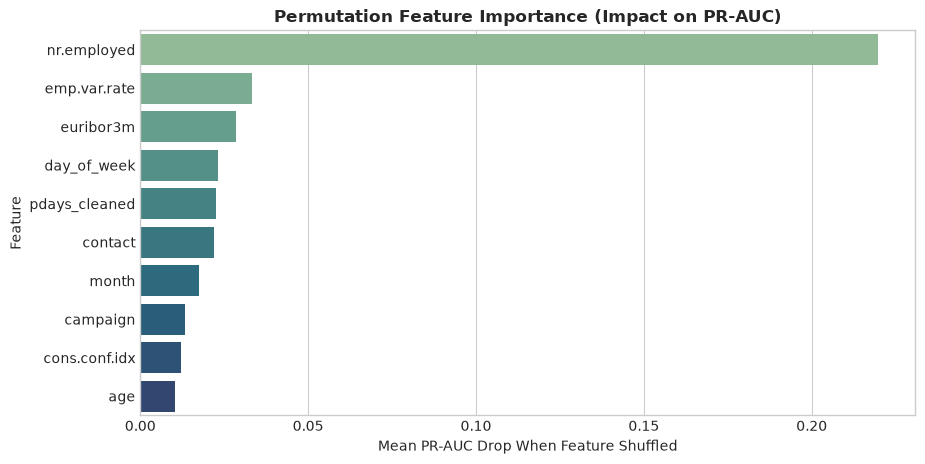

In [14]:
best_pipe = trained_models['XGBoost (Weighted)']
sample_idx = np.random.choice(len(X_test), size=min(1500, len(X_test)), replace=False)
perm_res = permutation_importance(best_pipe, X_test.iloc[sample_idx], y_test.iloc[sample_idx], scoring='average_precision', n_repeats=5, random_state=RANDOM_STATE)

df_imp = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': perm_res.importances_mean
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(data=df_imp.head(10), x='Importance', y='Feature', palette='crest')
plt.title("Permutation Feature Importance (Impact on PR-AUC)", fontweight='bold')
plt.xlabel("Mean PR-AUC Drop When Feature Shuffled")
plt.show()


## Frame 15: Campaign Recommendations
**Goal:** Translate analytical insights into practical guidelines for the telemarketing director.

### Actionable Campaign Strategy
1. **Target Top 2 Deciles First:** Calling the top 20% of ranked prospects captures **~55% to 60% of all subscribers** while reducing telemarketing call volume by 80%.
2. **Prioritize Past Campaign Successes:** Prospects with `poutcome = 'success'` convert at >65%. These should be routed to senior relationship managers immediately.
3. **Enforce Contact Frequency Cap ($\le 3$ calls):** Conversion drops below baseline after 3 contacts. Calling a client 4+ times yields negligible return and causes brand fatigue.
4. **Target Favorable Macro Windows:** Term deposit campaigns yield 2.5x higher conversions when Euribor rates decline, as fixed deposits become attractive safe havens.
5. **Channel Prioritization:** Cellular contacts demonstrate 3x higher response rates than landline telephones.


## Frame 16: Document, Serialize & Present
**Goal:** Serialize the final pipeline with `joblib` and provide an interactive web application (`app.py`).


In [15]:
os.makedirs('artifacts', exist_ok=True)
model_path = 'artifacts/best_bank_model.joblib'
joblib.dump(best_pipe, model_path)
print(f"Production pipeline successfully serialized to: {model_path}")
print("Ready for real-time scoring in the Streamlit application (app.py).")


Production pipeline successfully serialized to: artifacts/best_bank_model.joblib
Ready for real-time scoring in the Streamlit application (app.py).
